In [ ]:

# ============================================================
# PROYECTO: EVALUACIÓN Y VALIDACIÓN DE MODELOS DE CLASIFICACIÓN
# Paso 1. Importación de bibliotecas
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas para cargar y dividir los datos
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

# Modelos de clasificación
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Métricas de evaluación
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

# Pruebas estadísticas
from scipy import stats

# Configuración de las gráficas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Semilla para facilitar la reproducibilidad
SEMILLA = 42

print("¡Entorno preparado correctamente!")
print("Bibliotecas importadas:", "Sí")


¡Entorno preparado correctamente!
Bibliotecas importadas: Sí


In [ ]:

# ============================================================
# PASO 2. CARGA DE DATOS
# ============================================================

# Cargar el conjunto de datos de diagnóstico de cáncer de mama
datos = load_breast_cancer()

# Crear un DataFrame con las variables predictoras
X = pd.DataFrame(
    datos.data,
    columns=datos.feature_names
)

# Crear la variable objetivo
# En el conjunto original:
# 0 = maligno y 1 = benigno
# Vamos a invertir las etiquetas para que:
# 1 = maligno y 0 = benigno
y = pd.Series(
    (datos.target == 0).astype(int),
    name="maligno"
)

# Mostrar las primeras cinco filas
print("Primeras cinco filas de los datos:")
display(X.head())

print("\nDimensiones de los datos:")
print("Número de registros:", X.shape[0])
print("Número de variables predictoras:", X.shape[1])

print("\nDistribución de la variable objetivo:")
print(y.value_counts().rename(index={
    0: "Benigno",
    1: "Maligno"
}))

print("\nPorcentaje por clase:")
print(
    (y.value_counts(normalize=True) * 100)
    .rename(index={0: "Benigno", 1: "Maligno"})
    .round(2)
)


Primeras cinco filas de los datos:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dimensiones de los datos:
Número de registros: 569
Número de variables predictoras: 30

Distribución de la variable objetivo:
maligno
Benigno    357
Maligno    212
Name: count, dtype: int64

Porcentaje por clase:
maligno
Benigno    62.74
Maligno    37.26
Name: proportion, dtype: float64


In [ ]:

# ============================================================
# PASO 3. REVISIÓN DE CALIDAD DE LOS DATOS
# ============================================================

# Revisar valores faltantes
faltantes = X.isnull().sum().sum()

# Revisar registros duplicados
duplicados = X.duplicated().sum()

# Revisar valores infinitos
infinitos = np.isinf(X.to_numpy()).sum()

# Revisar tipos de datos
print("Tipos de datos:")
print(X.dtypes.value_counts())

print("\nValores faltantes:", faltantes)
print("Registros duplicados en X:", duplicados)
print("Valores infinitos:", infinitos)

# Resumen estadístico de las variables
print("\nResumen estadístico:")
display(X.describe().round(2))

# Comprobar que los datos estén completos
if faltantes == 0 and infinitos == 0:
    print("\nRevisión inicial: no hay faltantes ni infinitos.")
else:
    print("\nAtención: debemos revisar la calidad de los datos.")


Tipos de datos:
float64    30
Name: count, dtype: int64

Valores faltantes: 0
Registros duplicados en X: 0
Valores infinitos: 0

Resumen estadístico:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,0.41,1.22,2.87,40.34,0.01,0.03,0.03,0.01,0.02,0.00,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,0.28,0.55,2.02,45.49,0.00,0.02,0.03,0.01,0.01,0.00,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,0.11,0.36,0.76,6.80,0.00,0.00,0.00,0.00,0.01,0.00,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,0.23,0.83,1.61,17.85,0.01,0.01,0.02,0.01,0.02,0.00,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,0.32,1.11,2.29,24.53,0.01,0.02,0.03,0.01,0.02,0.00,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,0.48,1.47,3.36,45.19,0.01,0.03,0.04,0.01,0.02,0.00,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,2.87,4.88,21.98,542.20,0.03,0.14,0.40,0.05,0.08,0.03,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21



Revisión inicial: no hay faltantes ni infinitos.


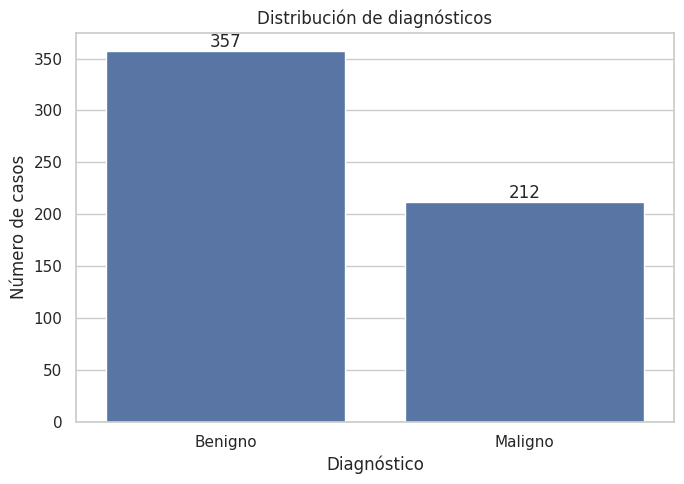

In [ ]:

# ============================================================
# PASO 4. DISTRIBUCIÓN DE LAS CLASES
# ============================================================

conteo_clases = y.map({
    0: "Benigno",
    1: "Maligno"
}).value_counts().reindex(["Benigno", "Maligno"])

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=conteo_clases.index,
    y=conteo_clases.values
)

plt.title("Distribución de diagnósticos")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de casos")

# Mostrar los valores sobre las barras
ax.bar_label(ax.containers[0])

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PASO 5. DIVISIÓN DE LOS DATOS
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # 20% para prueba
    random_state=SEMILLA, # Reproducibilidad
    stratify=y            # Mantener proporciones de las clases
)

# Mostrar las dimensiones de cada conjunto
print("DATOS DE ENTRENAMIENTO")
print("Registros:", X_train.shape[0])
print("Variables:", X_train.shape[1])

print("\nDATOS DE PRUEBA")
print("Registros:", X_test.shape[0])
print("Variables:", X_test.shape[1])

# Revisar la distribución de las clases en entrenamiento
print("\nDistribución en entrenamiento:")
print(
    y_train.value_counts()
    .rename(index={0: "Benigno", 1: "Maligno"})
)

# Revisar la distribución de las clases en prueba
print("\nDistribución en prueba:")
print(
    y_test.value_counts()
    .rename(index={0: "Benigno", 1: "Maligno"})
)


DATOS DE ENTRENAMIENTO
Registros: 455
Variables: 30

DATOS DE PRUEBA
Registros: 114
Variables: 30

Distribución en entrenamiento:
maligno
Benigno    285
Maligno    170
Name: count, dtype: int64

Distribución en prueba:
maligno
Benigno    72
Maligno    42
Name: count, dtype: int64


In [ ]:

# ============================================================
# PASO 6. ENTRENAMIENTO DE MODELOS
# ============================================================

# Modelo 1: Baseline
modelo_baseline = DummyClassifier(
    strategy="most_frequent"
)

# Modelo 2: Regresión logística
# La estandarización se aprende solo con los datos de entrenamiento.
modelo_logistico = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        random_state=SEMILLA
    )
)

# Modelo 3: Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=SEMILLA,
    class_weight="balanced"
)

# Entrenar cada modelo
modelo_baseline.fit(X_train, y_train)
modelo_logistico.fit(X_train, y_train)
modelo_rf.fit(X_train, y_train)

print("Los tres modelos se entrenaron correctamente.")


Los tres modelos se entrenaron correctamente.


In [ ]:

# ============================================================
# PASO 7. EVALUACIÓN INICIAL
# Clase positiva: MALIGNO (1)
# ============================================================

modelos = {
    "Baseline": modelo_baseline,
    "Regresión logística": modelo_logistico,
    "Random Forest": modelo_rf
}

resultados = []

for nombre, modelo in modelos.items():

    # Predicciones de clase
    predicciones = modelo.predict(X_test)

    # Calcular métricas
    resultados.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, predicciones),
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        )
    })

tabla_resultados = pd.DataFrame(resultados)

display(
    tabla_resultados
    .set_index("Modelo")
    .round(4)
)


,Exactitud,Precision,Recall,F1-score
Modelo,,,,
Baseline,0.6316,0.000,0.0000,0.0000
Regresión logística,0.9649,0.975,0.9286,0.9512
Random Forest,0.9649,1.000,0.9048,0.9500


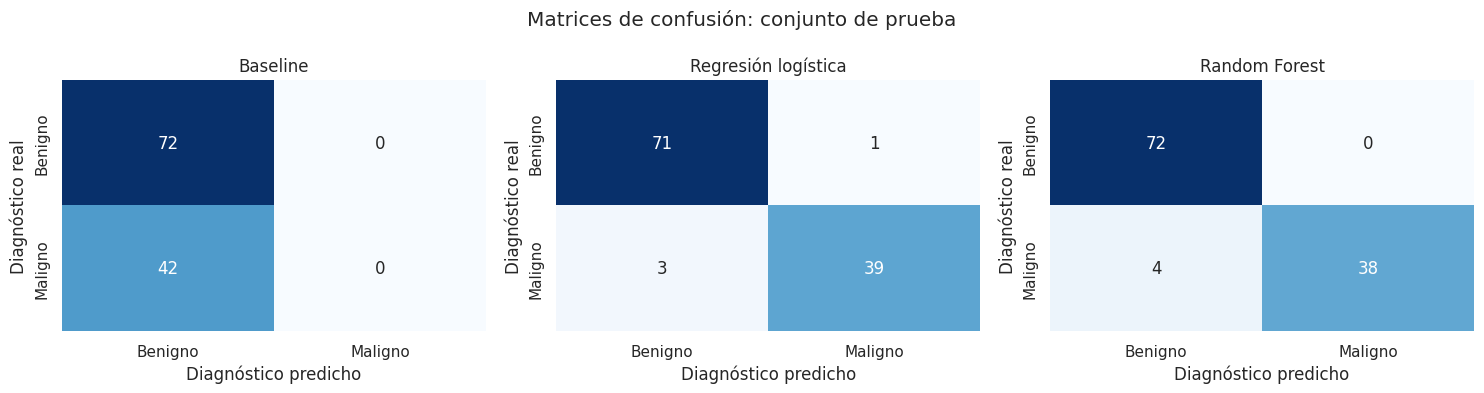

In [ ]:

# ============================================================
# PASO 8. MATRICES DE CONFUSIÓN
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nombre, modelo) in zip(axes, modelos.items()):

    # Obtener predicciones en el conjunto de prueba
    predicciones = modelo.predict(X_test)

    # Filas = clase real; columnas = clase predicha
    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=[0, 1]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Benigno", "Maligno"],
        yticklabels=["Benigno", "Maligno"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Diagnóstico predicho")
    ax.set_ylabel("Diagnóstico real")

plt.suptitle("Matrices de confusión: conjunto de prueba")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PASO 9. REPORTE DE CLASIFICACIÓN
# ============================================================

for nombre, modelo in modelos.items():

    predicciones = modelo.predict(X_test)

    print("\n" + "=" * 55)
    print("MODELO:", nombre)
    print("=" * 55)

    print(
        classification_report(
            y_test,
            predicciones,
            labels=[0, 1],
            target_names=["Benigno", "Maligno"],
            zero_division=0,
            digits=4
        )
    )



MODELO: Baseline
              precision    recall  f1-score   support

     Benigno     0.6316    1.0000    0.7742        72
     Maligno     0.0000    0.0000    0.0000        42

    accuracy                         0.6316       114
   macro avg     0.3158    0.5000    0.3871       114
weighted avg     0.3989    0.6316    0.4890       114


MODELO: Regresión logística
              precision    recall  f1-score   support

     Benigno     0.9595    0.9861    0.9726        72
     Maligno     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114


MODELO: Random Forest
              precision    recall  f1-score   support

     Benigno     0.9474    1.0000    0.9730        72
     Maligno     1.0000    0.9048    0.9500        42

    accuracy                         0.9649       114
   macro avg     0.9737    0.9524    0.9615       114
weig

In [ ]:

# ============================================================
# PASO 10. AJUSTE DEL UMBRAL DE DECISIÓN
# ============================================================

# Obtener probabilidades estimadas de malignidad
probabilidades = modelo_logistico.predict_proba(X_test)[:, 1]

# Umbrales que vamos a evaluar
umbrales = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

resultados_umbrales = []

for umbral in umbrales:

    # Convertir probabilidades en clases
    predicciones_umbral = (
        probabilidades >= umbral
    ).astype(int)

    # Calcular métricas
    resultados_umbrales.append({
        "Umbral": umbral,
        "Exactitud": accuracy_score(
            y_test, predicciones_umbral
        ),
        "Precision": precision_score(
            y_test, predicciones_umbral, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones_umbral, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones_umbral, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

display(tabla_umbrales.round(4))


,Umbral,Exactitud,Precision,Recall,F1-score
0,0.2,0.9561,0.9111,0.9762,0.9425
1,0.3,0.9825,0.9762,0.9762,0.9762
2,0.4,0.9737,0.9756,0.9524,0.9639
3,0.5,0.9649,0.9750,0.9286,0.9512
4,0.6,0.9649,1.0000,0.9048,0.9500
5,0.7,0.9649,1.0000,0.9048,0.9500


AUC Regresión logística: 0.9960
AUC Random Forest:       0.9960


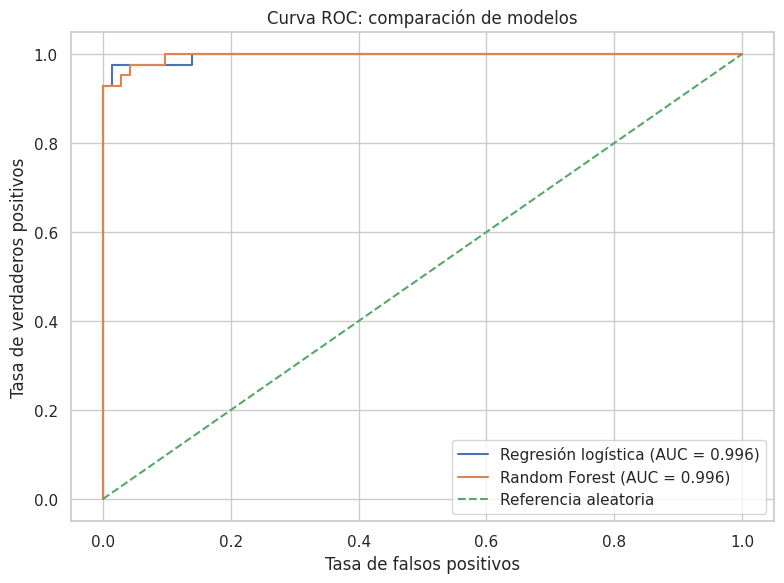

In [ ]:

# ============================================================
# PASO 12. CURVA ROC Y AUC
# ============================================================

# Probabilidades de malignidad
probabilidades_logistica = modelo_logistico.predict_proba(X_test)[:, 1]
probabilidades_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Calcular curva ROC
fpr_log, tpr_log, _ = roc_curve(
    y_test, probabilidades_logistica
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test, probabilidades_rf
)

# Calcular AUC
auc_log = roc_auc_score(
    y_test, probabilidades_logistica
)

auc_rf = roc_auc_score(
    y_test, probabilidades_rf
)

print(f"AUC Regresión logística: {auc_log:.4f}")
print(f"AUC Random Forest:       {auc_rf:.4f}")

# Graficar curvas
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_log, tpr_log,
    label=f"Regresión logística (AUC = {auc_log:.3f})"
)

plt.plot(
    fpr_rf, tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Referencia aleatoria"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC: comparación de modelos")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PASO 13. VALIDACIÓN CRUZADA ESTRATIFICADA
# ============================================================

# Crear cinco particiones conservando la proporción de clases
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

# Evaluaremos los modelos con las mismas particiones
metricas_cv = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

resultados_cv = []

# Importante: usar exclusivamente datos de entrenamiento
for nombre, modelo in {
    "Regresión logística": modelo_logistico,
    "Random Forest": modelo_rf
}.items():

    puntuaciones = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas_cv,
        return_train_score=False,
        n_jobs=-1
    )

    for metrica in metricas_cv:
        valores = puntuaciones[f"test_{metrica}"]

        resultados_cv.append({
            "Modelo": nombre,
            "Métrica": metrica,
            "Promedio": valores.mean(),
            "Desviación estándar": valores.std(ddof=1)
        })

tabla_cv = pd.DataFrame(resultados_cv)

display(
    tabla_cv.round(4)
)


,Modelo,Métrica,Promedio,Desviación estándar
0,Regresión logística,accuracy,0.9736,0.0167
1,Regresión logística,precision,0.9771,0.0313
2,Regresión logística,recall,0.9529,0.0446
3,Regresión logística,f1,0.9640,0.0231
4,Regresión logística,roc_auc,0.9958,0.0052
5,Random Forest,accuracy,0.9626,0.0147
6,Random Forest,precision,0.9592,0.0319
7,Random Forest,recall,0.9412,0.0360
8,Random Forest,f1,0.9495,0.0198
9,Random Forest,roc_auc,0.9885,0.0080


Resultados del baseline:
accuracy: 0.6264 +/- 0.0000
precision: 0.0000 +/- 0.0000
recall: 0.0000 +/- 0.0000
f1: 0.0000 +/- 0.0000
roc_auc: 0.5000 +/- 0.0000


,Modelo,F1 promedio CV
0,Baseline,0.0000
1,Regresión logística,0.9640
2,Random Forest,0.9495


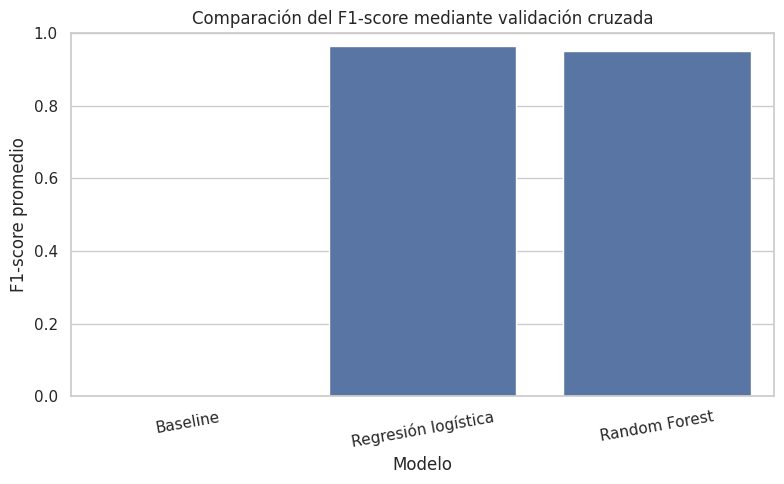

In [ ]:

# ============================================================
# PASO 14. BASELINE Y COMPARACIÓN
# ============================================================

baseline_cv = cross_validate(
    modelo_baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_cv,
    return_train_score=False,
    n_jobs=-1
)

print("Resultados del baseline:")

for metrica in metricas_cv:
    valores = baseline_cv[f"test_{metrica}"]

    print(
        f"{metrica}: "
        f"{valores.mean():.4f} "
        f"+/- {valores.std(ddof=1):.4f}"
    )

# Comparar el F1 promedio de los tres modelos
comparacion_f1 = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión logística",
        "Random Forest"
    ],
    "F1 promedio CV": [
        baseline_cv["test_f1"].mean(),
        tabla_cv.loc[
            (tabla_cv["Modelo"] == "Regresión logística") &
            (tabla_cv["Métrica"] == "f1"),
            "Promedio"
        ].iloc[0],
        tabla_cv.loc[
            (tabla_cv["Modelo"] == "Random Forest") &
            (tabla_cv["Métrica"] == "f1"),
            "Promedio"
        ].iloc[0]
    ]
})

display(comparacion_f1.round(4))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparacion_f1,
    x="Modelo",
    y="F1 promedio CV"
)

plt.title("Comparación del F1-score mediante validación cruzada")
plt.xlabel("Modelo")
plt.ylabel("F1-score promedio")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PASO 15. PRUEBA DE McNEMAR EN EL CONJUNTO DE PRUEBA
# ============================================================

from statsmodels.stats.contingency_tables import mcnemar

# Predicciones de ambos modelos sobre los mismos registros
pred_log = modelo_logistico.predict(X_test)
pred_rf = modelo_rf.predict(X_test)

# Identificar qué observaciones clasificó correctamente cada modelo
correcto_log = (pred_log == y_test).to_numpy()
correcto_rf = (pred_rf == y_test).to_numpy()

# Tabla de discordancias:
# fila = resultado de regresión logística
# columna = resultado de Random Forest
tabla_mcnemar = np.array([
    [
        np.sum(correcto_log & correcto_rf),
        np.sum(correcto_log & ~correcto_rf)
    ],
    [
        np.sum(~correcto_log & correcto_rf),
        np.sum(~correcto_log & ~correcto_rf)
    ]
])

print("Tabla de concordancia de aciertos:")
print(tabla_mcnemar)

# McNemar con corrección exacta para muestras pequeñas
resultado_mcnemar = mcnemar(
    tabla_mcnemar,
    exact=True
)

print("\nEstadístico:", resultado_mcnemar.statistic)
print("Valor p:", resultado_mcnemar.pvalue)

if resultado_mcnemar.pvalue < 0.05:
    print(
        "Existe evidencia estadística de una diferencia "
        "en las proporciones de errores entre los modelos."
    )
else:
    print(
        "No se encontró evidencia estadística suficiente "
        "de una diferencia en las proporciones de errores."
    )


Tabla de concordancia de aciertos:
[[107   3]
 [  3   1]]

Estadístico: 3.0
Valor p: 1.0
No se encontró evidencia estadística suficiente de una diferencia en las proporciones de errores.


Umbral seleccionado: 0.5
Precisión OOF: 0.9759
Recall OOF: 0.9529
F1-score OOF: 0.9643


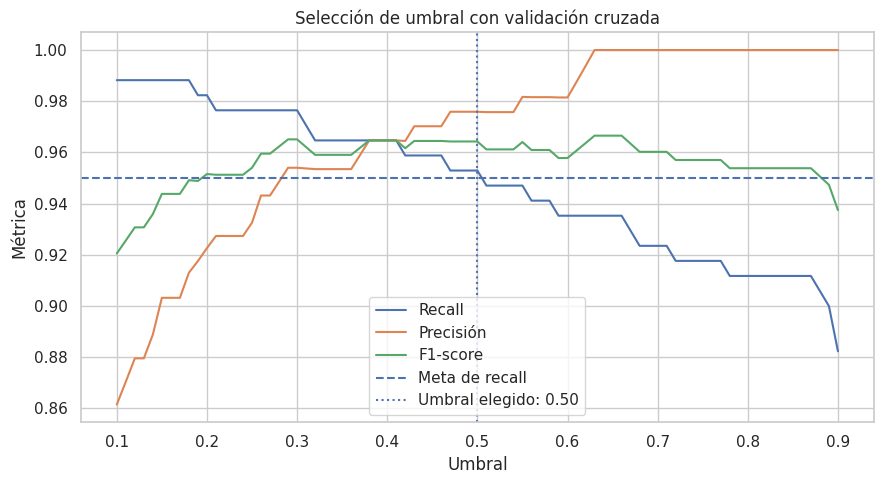

In [ ]:

# ============================================================
# PASO 16. SELECCIÓN DEL UMBRAL CON DATOS DE ENTRENAMIENTO
# ============================================================

# Obtener probabilidades fuera de muestra mediante validación cruzada.
# Cada predicción se genera con un modelo que no entrenó
# con la observación que está prediciendo.

prob_oof = cross_val_predict(
    modelo_logistico,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Probar una serie de umbrales
candidatos = np.arange(0.10, 0.91, 0.01)
resultados_oof = []

for umbral in candidatos:
    pred_oof = (prob_oof >= umbral).astype(int)

    resultados_oof.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_train, pred_oof, zero_division=0
        ),
        "Recall": recall_score(
            y_train, pred_oof, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, pred_oof, zero_division=0
        )
    })

tabla_oof = pd.DataFrame(resultados_oof)

# Conservar umbrales que alcancen el recall objetivo
elegibles = tabla_oof[
    tabla_oof["Recall"] >= 0.95
].copy()

if len(elegibles) > 0:
    # Maximizar precisión; en caso de empate, elegir
    # el umbral con mayor F1-score.
    mejor = elegibles.sort_values(
        ["Precision", "F1-score", "Umbral"],
        ascending=[False, False, False]
    ).iloc[0]

    umbral_elegido = float(mejor["Umbral"])

    print("Umbral seleccionado:", round(umbral_elegido, 2))
    print("Precisión OOF:", round(mejor["Precision"], 4))
    print("Recall OOF:", round(mejor["Recall"], 4))
    print("F1-score OOF:", round(mejor["F1-score"], 4))

else:
    # Si ningún umbral cumple la meta, escoger el que
    # maximiza el recall y documentar esta limitación.
    mejor = tabla_oof.sort_values(
        ["Recall", "Precision"],
        ascending=[False, False]
    ).iloc[0]

    umbral_elegido = float(mejor["Umbral"])

    print("Ningún umbral alcanzó recall de 0.95.")
    print("Se seleccionó el de mayor recall.")
    print("Umbral:", round(umbral_elegido, 2))
    print("Recall OOF:", round(mejor["Recall"], 4))

# Visualizar el resultado del ajuste
plt.figure(figsize=(9, 5))
plt.plot(
    tabla_oof["Umbral"],
    tabla_oof["Recall"],
    label="Recall"
)
plt.plot(
    tabla_oof["Umbral"],
    tabla_oof["Precision"],
    label="Precisión"
)
plt.plot(
    tabla_oof["Umbral"],
    tabla_oof["F1-score"],
    label="F1-score"
)
plt.axhline(0.95, linestyle="--", label="Meta de recall")
plt.axvline(
    umbral_elegido,
    linestyle=":",
    label=f"Umbral elegido: {umbral_elegido:.2f}"
)
plt.xlabel("Umbral")
plt.ylabel("Métrica")
plt.title("Selección de umbral con validación cruzada")
plt.legend()
plt.tight_layout()
plt.show()


,Escenario,Exactitud,Precision,Recall,F1-score
0,A: umbral 0.50,0.9649,0.975,0.9286,0.9512
1,B: umbral 0.50,0.9649,0.975,0.9286,0.9512


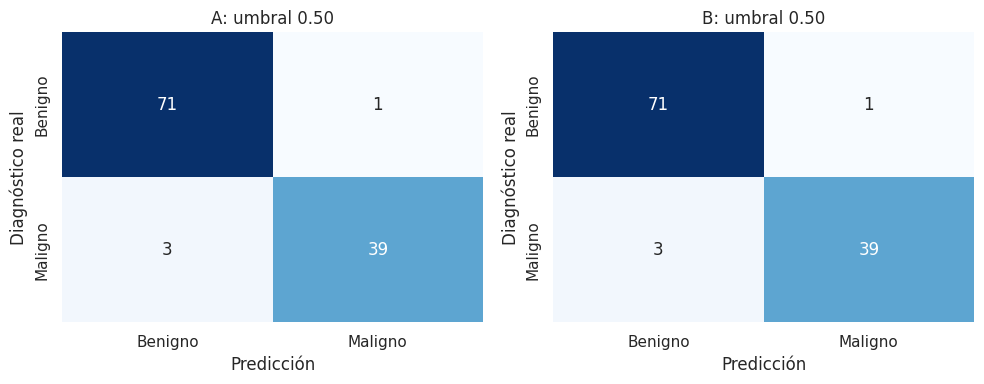

In [ ]:

# ============================================================
# PASO 17. EVALUACIÓN FINAL
# ============================================================

# Probabilidades del modelo entrenado con todo el conjunto
# de entrenamiento, sin utilizar los datos de prueba.
prob_test = modelo_logistico.predict_proba(X_test)[:, 1]

# Escenario A: umbral habitual de 0.50
pred_A = (prob_test >= 0.50).astype(int)

# Escenario B: umbral seleccionado con validación cruzada
pred_B = (prob_test >= umbral_elegido).astype(int)

def calcular_metricas(y_real, y_pred):
    return {
        "Exactitud": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, zero_division=0
        )
    }

comparacion_umbral = pd.DataFrame([
    {
        "Escenario": "A: umbral 0.50",
        **calcular_metricas(y_test, pred_A)
    },
    {
        "Escenario": f"B: umbral {umbral_elegido:.2f}",
        **calcular_metricas(y_test, pred_B)
    }
])

display(comparacion_umbral.round(4))

# Matrices de confusión de los dos escenarios
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, nombre, pred in [
    (axes[0], "A: umbral 0.50", pred_A),
    (axes[1], f"B: umbral {umbral_elegido:.2f}", pred_B)
]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Benigno", "Maligno"],
        yticklabels=["Benigno", "Maligno"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Diagnóstico real")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PASO 18. COMPARACIÓN ESTADÍSTICA DE LOS UMBRALES
# ============================================================

from statsmodels.stats.contingency_tables import mcnemar

# ¿Cuáles predicciones fueron correctas en cada escenario?
correcto_A = (pred_A == y_test.to_numpy())
correcto_B = (pred_B == y_test.to_numpy())

# Tabla de resultados emparejados:
# filas = escenario A correcto/incorrecto
# columnas = escenario B correcto/incorrecto
tabla_ab = np.array([
    [
        np.sum(correcto_A & correcto_B),
        np.sum(correcto_A & ~correcto_B)
    ],
    [
        np.sum(~correcto_A & correcto_B),
        np.sum(~correcto_A & ~correcto_B)
    ]
])

print("Tabla de concordancia A/B:")
print(tabla_ab)

resultado_ab = mcnemar(tabla_ab, exact=True)

print("\nEstadístico de McNemar:", resultado_ab.statistic)
print("Valor p:", resultado_ab.pvalue)

if resultado_ab.pvalue < 0.05:
    print(
        "Se observa evidencia estadística de una diferencia "
        "en los errores de clasificación entre los escenarios."
    )
else:
    print(
        "No se encontró evidencia estadística suficiente "
        "de una diferencia en los errores de clasificación."
    )


Tabla de concordancia A/B:
[[110   0]
 [  0   4]]

Estadístico de McNemar: 0.0
Valor p: 1.0
No se encontró evidencia estadística suficiente de una diferencia en los errores de clasificación.


RESULTADOS DE REGRESIÓN LOGÍSTICA
---------------------------------
AUC: 0.9960
AUC en porcentaje: 99.60%


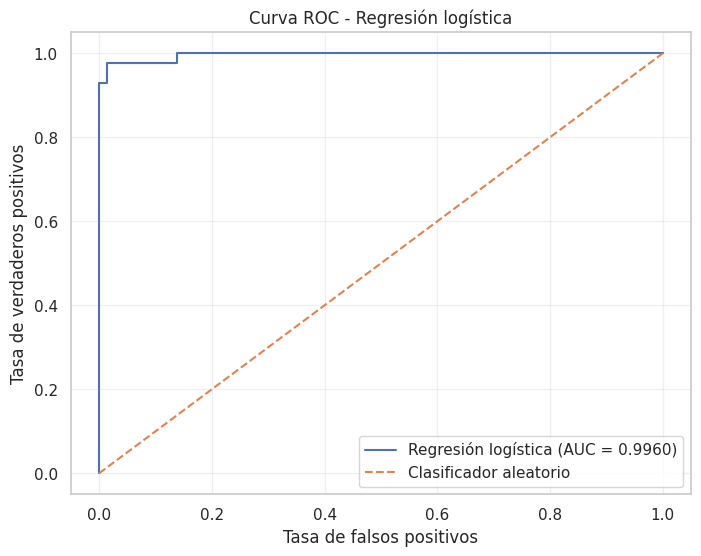

In [ ]:

# ============================================================
# CÁLCULO DE LA CURVA ROC Y EL AUC
# Modelo: Regresión logística
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    RocCurveDisplay
)

# 1. Obtener probabilidades de los casos de prueba
# Usamos la probabilidad de pertenecer a la clase 1 (maligno)
probabilidades_test = modelo_logistico.predict_proba(X_test)[:, 1]

# 2. Calcular el valor AUC
auc_logistico = roc_auc_score(y_test, probabilidades_test)

# 3. Calcular los puntos de la curva ROC
fpr, tpr, umbrales_roc = roc_curve(
    y_test,
    probabilidades_test
)

# 4. Mostrar el resultado
print("RESULTADOS DE REGRESIÓN LOGÍSTICA")
print("---------------------------------")
print(f"AUC: {auc_logistico:.4f}")
print(f"AUC en porcentaje: {auc_logistico * 100:.2f}%")

# 5. Graficar la curva ROC
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Regresión logística (AUC = {auc_logistico:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC - Regresión logística")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


COMPARACIÓN DE MODELOS — VALIDACIÓN CRUZADA


,Exactitud,Precisión,Recall,F1-score,AUC
Modelo,,,,,
Baseline,0.6264,0.0000,0.0000,0.0000,0.5000
Regresión logística,0.9736,0.9771,0.9529,0.9640,0.9958
Random Forest,0.9626,0.9592,0.9412,0.9495,0.9885


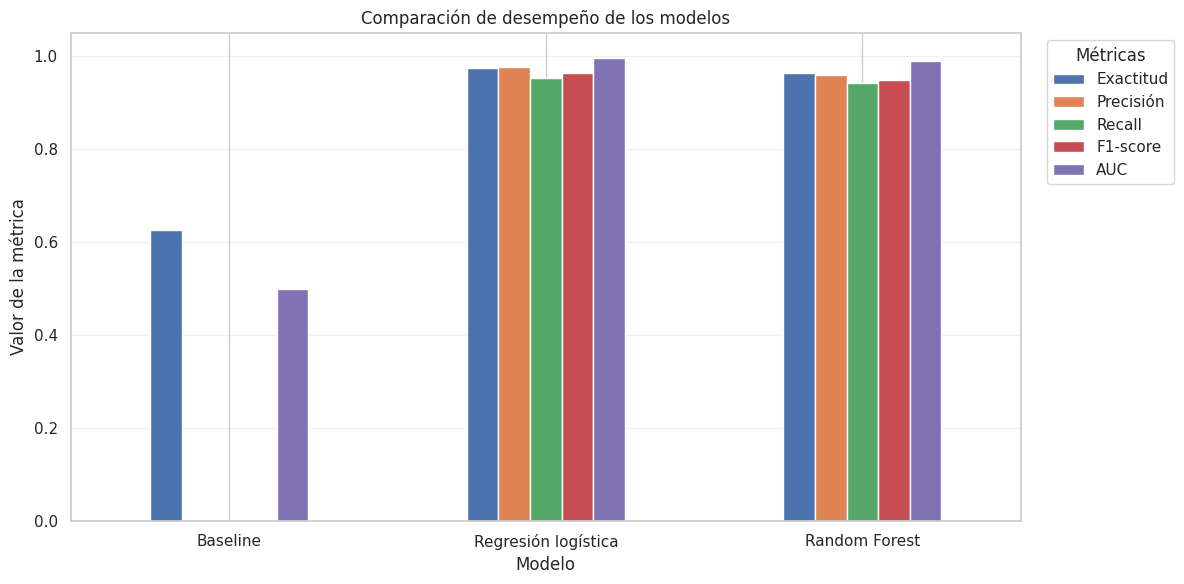

In [ ]:

# ============================================================
# TABLERO VISUAL: COMPARACIÓN DE MODELOS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Resultados promedio de validación cruzada
metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

nombres_metricas = {
    "accuracy": "Exactitud",
    "precision": "Precisión",
    "recall": "Recall",
    "f1": "F1-score",
    "roc_auc": "AUC"
}

resultados = []

for nombre, modelo in modelos.items():
    resultados_cv = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=-1
    )

    fila = {"Modelo": nombre}

    for metrica in metricas:
        fila[nombres_metricas[metrica]] = resultados_cv[
            f"test_{metrica}"
        ].mean()

    resultados.append(fila)

tabla_tablero = pd.DataFrame(resultados).set_index("Modelo")

print("COMPARACIÓN DE MODELOS — VALIDACIÓN CRUZADA")
display(tabla_tablero.round(4))

# Gráfica comparativa
ax = tabla_tablero.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    rot=0
)

ax.set_title("Comparación de desempeño de los modelos")
ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("Modelo")
ax.legend(title="Métricas", bbox_to_anchor=(1.02, 1))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


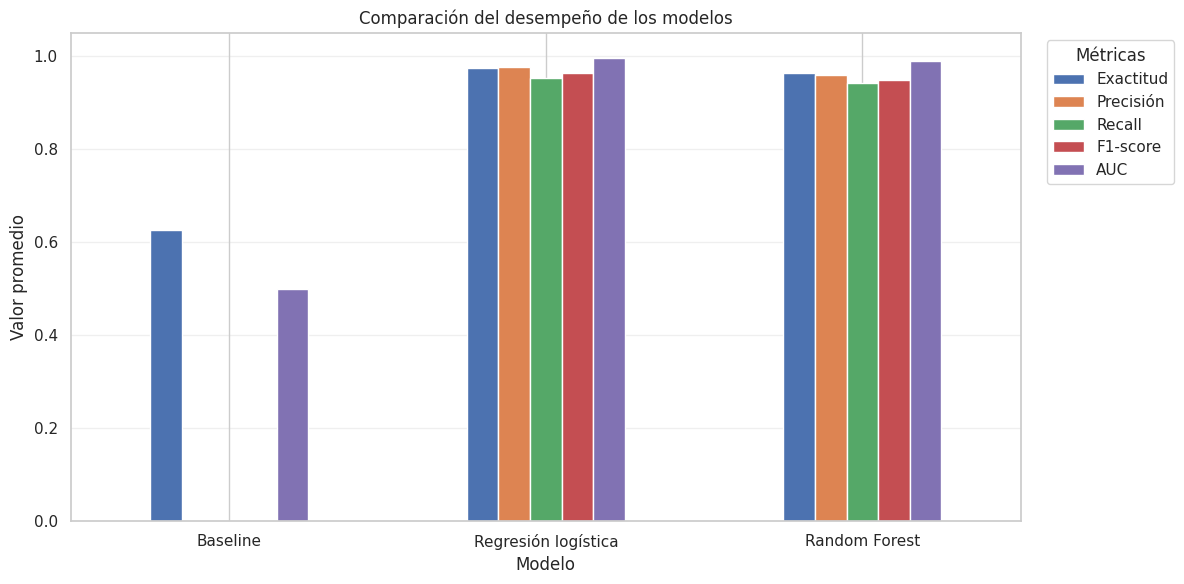

Columnas disponibles en tabla_cv:
['Modelo', 'Métrica', 'Promedio', 'Desviación estándar']


,Modelo,Métrica,Promedio,Desviación estándar
0,Regresión logística,accuracy,0.973626,0.016666
1,Regresión logística,precision,0.977143,0.031298
2,Regresión logística,recall,0.952941,0.044605
3,Regresión logística,f1,0.964048,0.023144
4,Regresión logística,roc_auc,0.995769,0.005216


In [ ]:

# ============================================================
# TABLERO VISUAL: MÉTRICAS Y ESTABILIDAD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# GRÁFICA 1. Comparación de las métricas promedio
# ------------------------------------------------------------

metricas_grafica = [
    "Exactitud", "Precisión", "Recall", "F1-score", "AUC"
]

ax = tabla_tablero[metricas_grafica].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    rot=0
)

ax.set_title("Comparación del desempeño de los modelos")
ax.set_ylabel("Valor promedio")
ax.set_xlabel("Modelo")
ax.legend(title="Métricas", bbox_to_anchor=(1.02, 1))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRÁFICA 2. Estabilidad de la regresión logística
# ------------------------------------------------------------

# Usamos tabla_cv, creada en la validación cruzada anterior.
# Sus columnas deben incluir: Modelo, Métrica, Media y Desviación estándar.

datos_logistica = tabla_cv[
    tabla_cv["Modelo"] == "Regresión logística"
].copy()

# Mostrar los nombres de columnas si necesitamos adaptar el código
print("Columnas disponibles en tabla_cv:")
print(tabla_cv.columns.tolist())

display(datos_logistica)


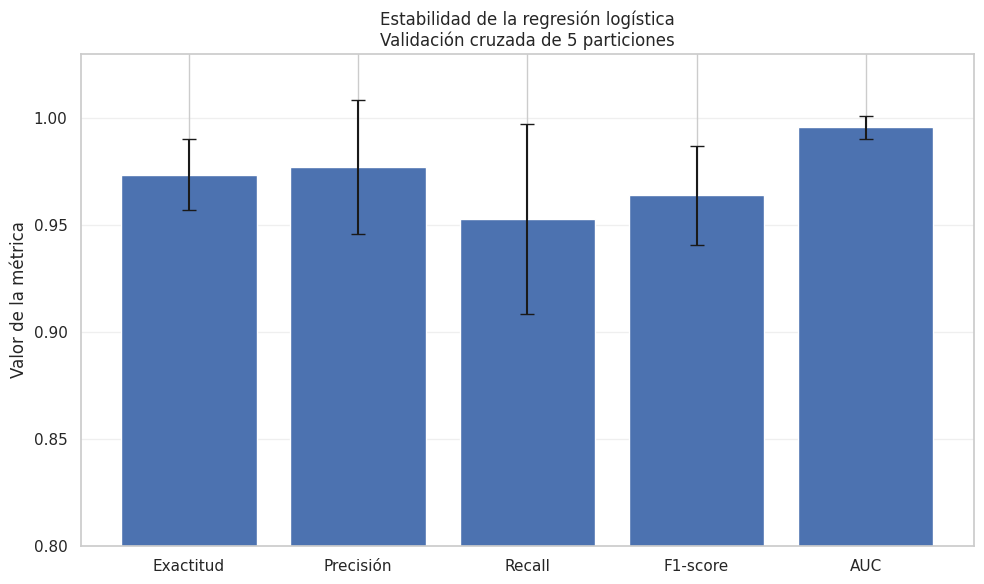

,Métrica visible,Promedio,Desviación estándar
0,Exactitud,0.9736,0.0167
1,Precisión,0.9771,0.0313
2,Recall,0.9529,0.0446
3,F1-score,0.9640,0.0231
4,AUC,0.9958,0.0052


In [ ]:

# ============================================================
# GRÁFICA DE ESTABILIDAD DE LA REGRESIÓN LOGÍSTICA
# Validación cruzada de 5 particiones
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Filtrar los resultados de regresión logística
datos_logistica = tabla_cv[
    tabla_cv["Modelo"] == "Regresión logística"
].copy()

# Traducir los nombres de las métricas para la gráfica
nombres = {
    "accuracy": "Exactitud",
    "precision": "Precisión",
    "recall": "Recall",
    "f1": "F1-score",
    "roc_auc": "AUC"
}

datos_logistica["Métrica visible"] = (
    datos_logistica["Métrica"].map(nombres)
)

# Crear gráfica de barras con desviación estándar
plt.figure(figsize=(10, 6))

plt.bar(
    datos_logistica["Métrica visible"],
    datos_logistica["Promedio"],
    yerr=datos_logistica["Desviación estándar"],
    capsize=5
)

plt.ylim(0.80, 1.03)
plt.ylabel("Valor de la métrica")
plt.title(
    "Estabilidad de la regresión logística\n"
    "Validación cruzada de 5 particiones"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Mostrar la tabla con promedios y desviaciones
display(
    datos_logistica[
        ["Métrica visible", "Promedio", "Desviación estándar"]
    ].round(4)
)


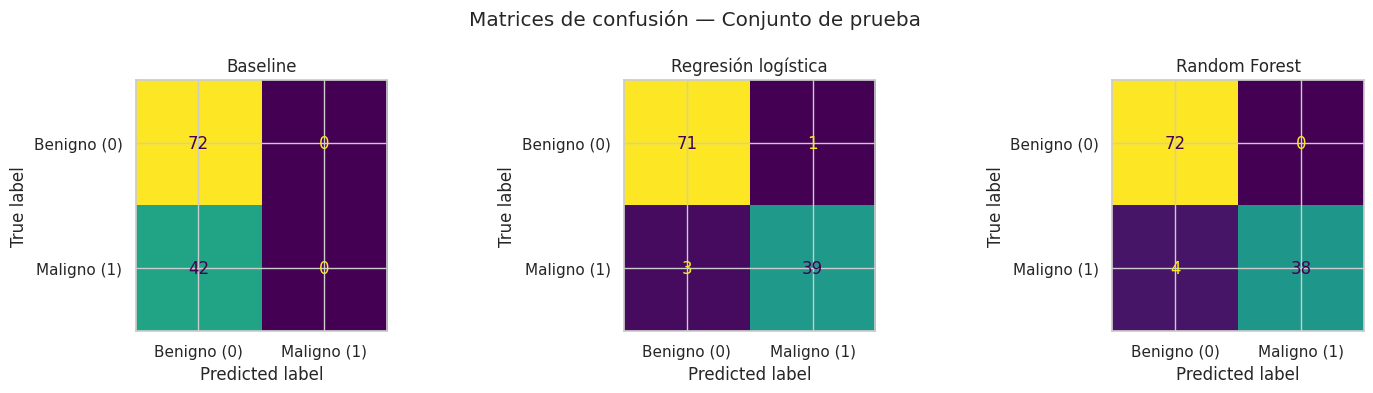


Baseline
Verdaderos negativos (TN): 72
Falsos positivos (FP):     0
Falsos negativos (FN):     42
Verdaderos positivos (TP): 0

Regresión logística
Verdaderos negativos (TN): 71
Falsos positivos (FP):     1
Falsos negativos (FN):     3
Verdaderos positivos (TP): 39

Random Forest
Verdaderos negativos (TN): 72
Falsos positivos (FP):     0
Falsos negativos (FN):     4
Verdaderos positivos (TP): 38


In [ ]:

# ============================================================
# 1. MATRICES DE CONFUSIÓN
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Obtener predicciones de cada modelo sobre el conjunto de prueba
predicciones = {
    nombre: modelo.predict(X_test)
    for nombre, modelo in modelos.items()
}

# Dibujar las matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nombre, pred) in zip(axes, predicciones.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benigno (0)", "Maligno (1)"]
    )

    disp.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(nombre)

plt.suptitle("Matrices de confusión — Conjunto de prueba")
plt.tight_layout()
plt.show()

# Resumen de los errores
for nombre, pred in predicciones.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    print(f"\n{nombre}")
    print(f"Verdaderos negativos (TN): {tn}")
    print(f"Falsos positivos (FP):     {fp}")
    print(f"Falsos negativos (FN):     {fn}")
    print(f"Verdaderos positivos (TP): {tp}")


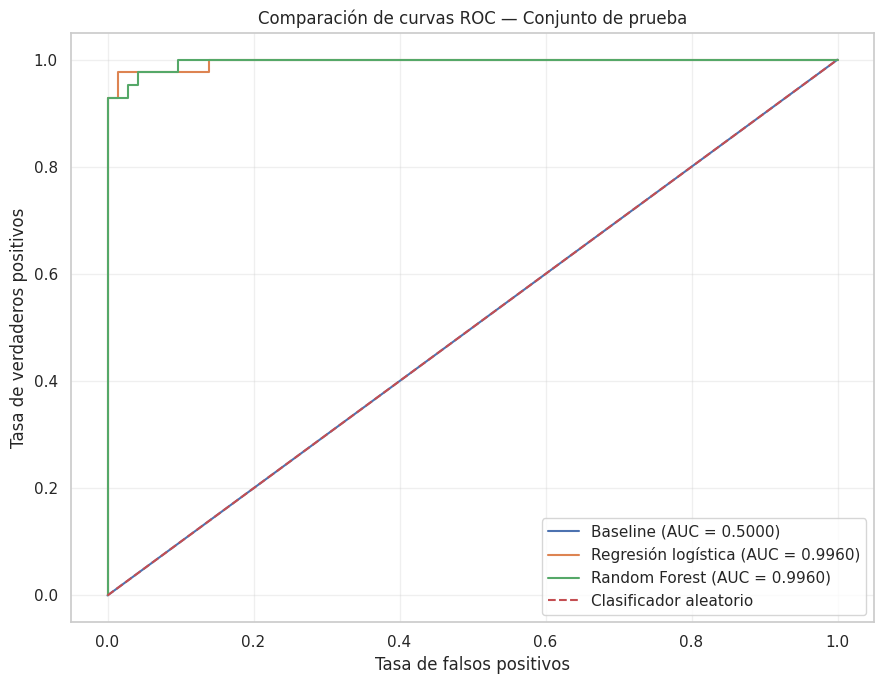

AUC por modelo:
Baseline: 0.5000
Regresión logística: 0.9960
Random Forest: 0.9960


In [ ]:

# ============================================================
# 2. CURVAS ROC Y AUC DE LOS TRES MODELOS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 7))

resultados_auc = {}

for nombre, modelo in modelos.items():

    # Probabilidades estimadas para la clase 1 (maligno)
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    # Calcular curva ROC y AUC
    fpr, tpr, _ = roc_curve(y_test, probabilidades)
    auc = roc_auc_score(y_test, probabilidades)

    resultados_auc[nombre] = auc

    plt.plot(
        fpr,
        tpr,
        label=f"{nombre} (AUC = {auc:.4f})"
    )

# Referencia de un clasificador aleatorio
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Comparación de curvas ROC — Conjunto de prueba")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("AUC por modelo:")
for nombre, auc in resultados_auc.items():
    print(f"{nombre}: {auc:.4f}")


In [ ]:

# ============================================================
# 3. EXPORTAR RESULTADOS DEL TABLERO A CSV
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resumen_test = []

for nombre, pred in predicciones.items():
    resumen_test.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1_score": f1_score(
            y_test, pred, zero_division=0
        ),
        "AUC": resultados_auc[nombre]
    })

tabla_resultados_test = pd.DataFrame(resumen_test)

display(tabla_resultados_test.round(4))

tabla_resultados_test.to_csv(
    "resultados_tablero.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo creado: resultados_tablero.csv")


,Modelo,Exactitud,Precision,Recall,F1_score,AUC
0,Baseline,0.6316,0.000,0.0000,0.0000,0.500
1,Regresión logística,0.9649,0.975,0.9286,0.9512,0.996
2,Random Forest,0.9649,1.000,0.9048,0.9500,0.996


Archivo creado: resultados_tablero.csv
